# 03 - Niagara Canadian Business Counts Exploratory Data Analysis (EDA)
**Deliverables:** 4.1, 4.4 | **Dataset:** Statistics Canada Table 33-10-1176-01 (Interim Niagara Slice)

## Objectives
1. Inspect dataset structure, columns, geography identifiers (DGUID), and reference period.
2. Analyze enterprise distributions across employment size categories without double counting.
3. Identify leading industries across Niagara Census Subdivisions.
4. Quantify micro- and small-business concentration.
5. Conduct a structured comparative review with the Niagara Employment Inventory (NEI).
6. Synthesize strategic findings for the Niagara succession signal pipeline.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('../../reports/figures', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 150

## Step 3: Inspect the Data
- Load cleaned interim CSV.
- Inspect dimensions, schema, and reference period.
- Validate DGUIDs against the 12 Niagara Census Subdivisions.

In [2]:
data_path = '../../data/interim/canadian_business_counts_niagara_cleaned.csv'
df = pd.read_csv(data_path)
print(f'Dataset shape: {df.shape[0]:,} rows, {df.shape[1]} columns')
df.head()

Dataset shape: 10,462 rows, 16 columns


,REF_DATE,GEO,DGUID,Employment size,North American Industry Classification System (NAICS),UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,2026-01,Grimsby,2021A00053526065,"Total, with employees","Total, all industries [1]",Number,223,units,0,v1918953682,323.1.1,814,NaN,NaN,NaN,0
1,2026-01,Grimsby,2021A00053526065,"Total, with employees",Unclassified [2],Number,223,units,0,v1918953696,323.1.2,52,NaN,NaN,NaN,0
2,2026-01,Grimsby,2021A00053526065,"Total, with employees","Sub-total, classified [3]",Number,223,units,0,v1918953712,323.1.3,762,NaN,NaN,NaN,0
3,2026-01,Grimsby,2021A00053526065,"Total, with employees","Agriculture, forestry, fishing and hunting [11]",Number,223,units,0,v1918953683,323.1.4,20,NaN,NaN,NaN,0
4,2026-01,Grimsby,2021A00053526065,"Total, with employees",Utilities [22],Number,223,units,0,v1918953697,323.1.6,2,NaN,NaN,NaN,0


In [3]:
print('--- Column Data Types & Non-Null Counts ---')
print(df.info())
print('\n--- Missing Values ---')
print(df.isna().sum())
print('\n--- Unique Reference Periods ---')
print(df['REF_DATE'].unique())
print('\n--- Municipalities (GEO) and DGUID count ---')
print(df.groupby(['GEO', 'DGUID']).size().reset_index(name='record_count'))

--- Column Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 10462 entries, 0 to 10461
Data columns (total 16 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   REF_DATE                                               10462 non-null  str    
 1   GEO                                                    10462 non-null  str    
 2   DGUID                                                  10462 non-null  str    
 3   Employment size                                        10462 non-null  str    
 4   North American Industry Classification System (NAICS)  10462 non-null  str    
 5   UOM                                                    10462 non-null  str    
 6   UOM_ID                                                 10462 non-null  int64  
 7   SCALAR_FACTOR                                          10462 non-null  str    
 8   SCALAR_ID    

## Step 4: Analyze Businesses by Size
Ensure aggregation does not double count aggregate totals with sub-categories.

         Employment size  VALUE
8  Total, with employees  14395
0       1 to 4 employees   7639
5       5 to 9 employees   2804
1     10 to 19 employees   1916
3     20 to 49 employees   1234
6     50 to 99 employees    528
2   100 to 199 employees    177
4   200 to 499 employees     75
7     500 plus employees     22


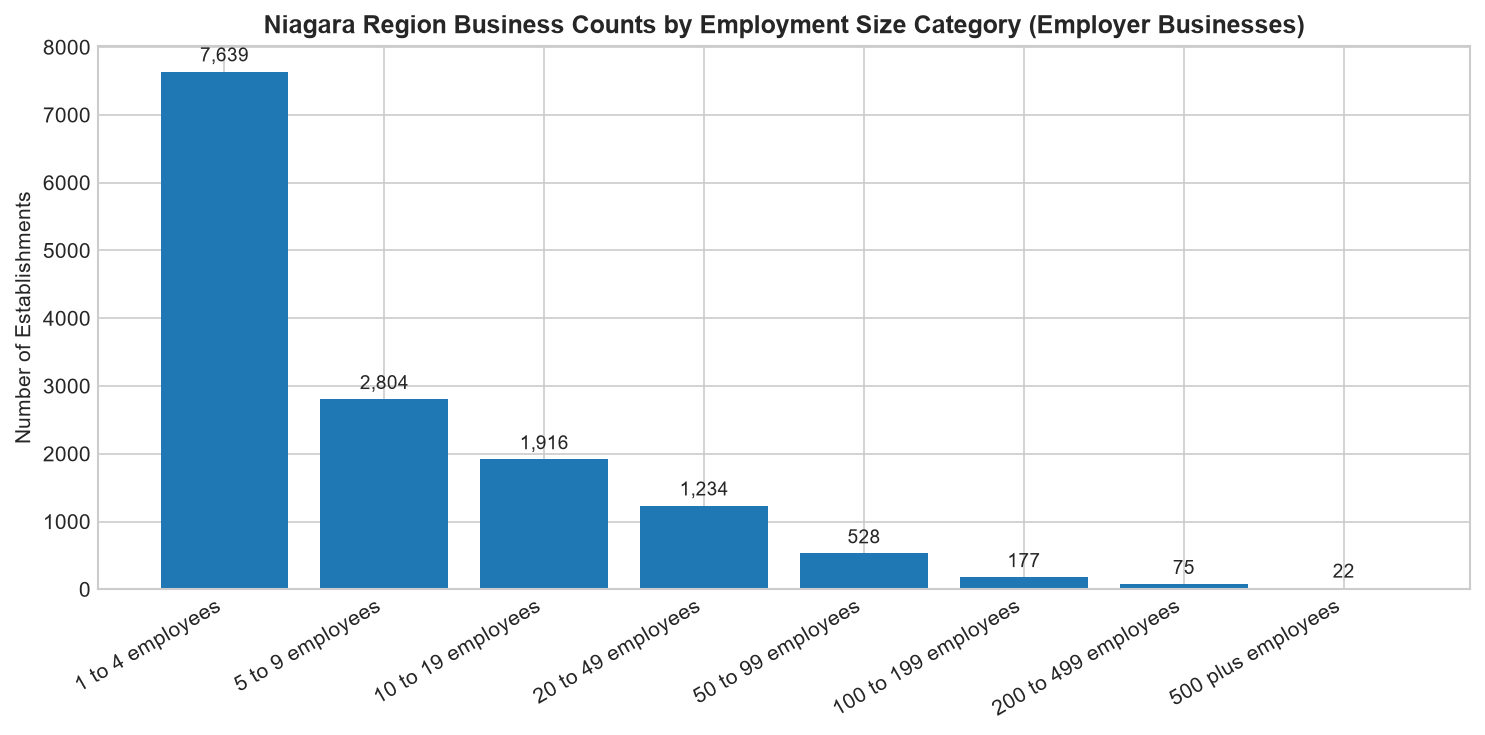

In [4]:
total_industry_mask = df['North American Industry Classification System (NAICS)'].str.startswith('Total, all industries', na=False)
df_total_ind = df[total_industry_mask].copy()

size_counts = df_total_ind.groupby('Employment size')['VALUE'].sum().reset_index()
size_counts = size_counts.sort_values(by='VALUE', ascending=False)
print(size_counts)

categories = [
    '1 to 4 employees', '5 to 9 employees', '10 to 19 employees',
    '20 to 49 employees', '50 to 99 employees', '100 to 199 employees',
    '200 to 499 employees', '500 plus employees'
]
size_plot_df = df_total_ind[df_total_ind['Employment size'].isin(categories)].groupby('Employment size')['VALUE'].sum().reindex(categories).fillna(0).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(size_plot_df['Employment size'], size_plot_df['VALUE'], color='#1f77b4')
plt.xticks(rotation=30, ha='right')
ax.set_ylabel('Number of Establishments')
ax.set_title('Niagara Region Business Counts by Employment Size Category (Employer Businesses)', fontsize=12, fontweight='bold')
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{int(height):,}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords='offset points',
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('../../reports/figures/niagara_business_counts_by_size.png')
plt.show()

## Step 5: Analyze Businesses by Industry
Filter to NAICS sectors (2-digit level) across total employment size to determine leading sectors.

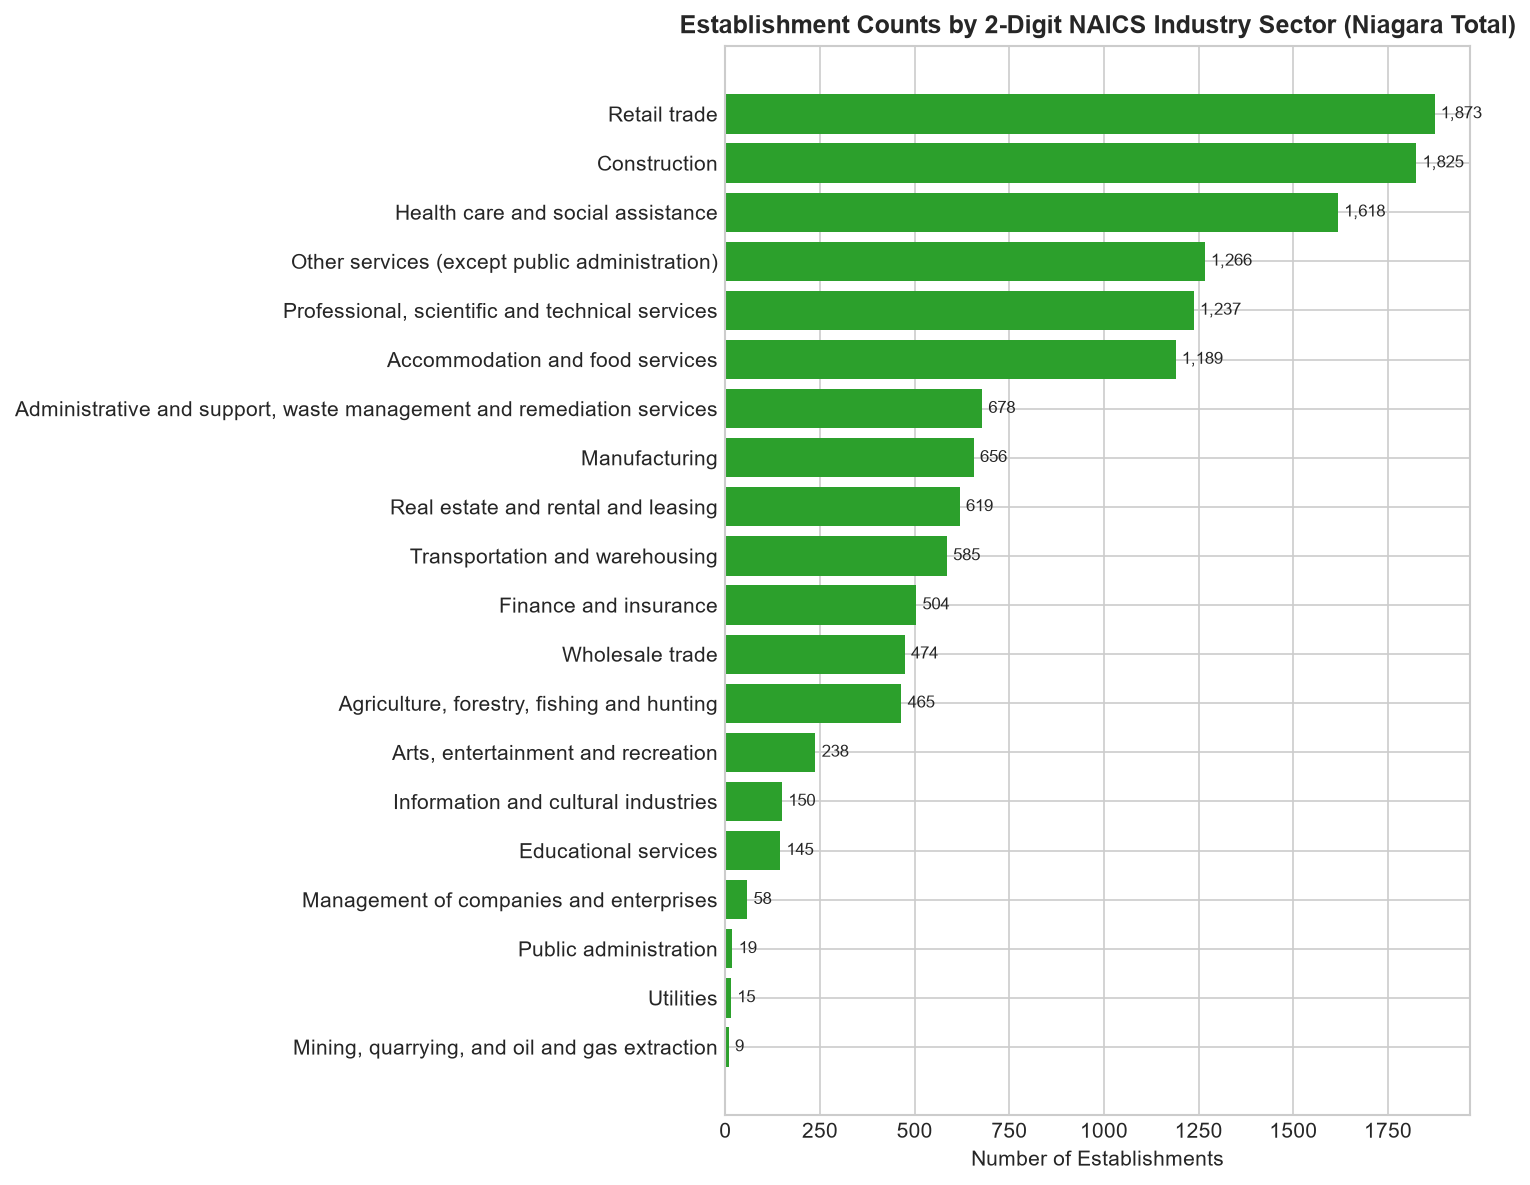

In [5]:
sector_mask = (
    (df['Employment size'] == 'Total, with employees') &
    (df['North American Industry Classification System (NAICS)'].str.contains(r'\[\d{2}\]|\[\d{2}-\d{2}\]', regex=True))
)
ind_df = df[sector_mask].groupby('North American Industry Classification System (NAICS)')['VALUE'].sum().reset_index()
ind_df['Industry_Clean'] = ind_df['North American Industry Classification System (NAICS)'].str.replace(r'\s*\[.*\]', '', regex=True)
ind_df = ind_df.sort_values(by='VALUE', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(ind_df['Industry_Clean'], ind_df['VALUE'], color='#2ca02c')
ax.set_xlabel('Number of Establishments')
ax.set_title('Establishment Counts by 2-Digit NAICS Industry Sector (Niagara Total)', fontsize=12, fontweight='bold')
for bar in bars:
    width = bar.get_width()
    ax.annotate(f'{int(width):,}',
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0),
                textcoords='offset points',
                ha='left', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('../../reports/figures/niagara_business_counts_by_industry.png')
plt.show()

## Step 6: Explore Small-Business Concentration
Calculate the percentage share of micro (1-4) and small (1-99) employer businesses relative to total employer businesses.

Total Employer Businesses (Denominator): 14,395
Micro Businesses (1-4 employees): 7,639 (53.07%)
Small Businesses (1-99 employees): 14,121 (98.10%)


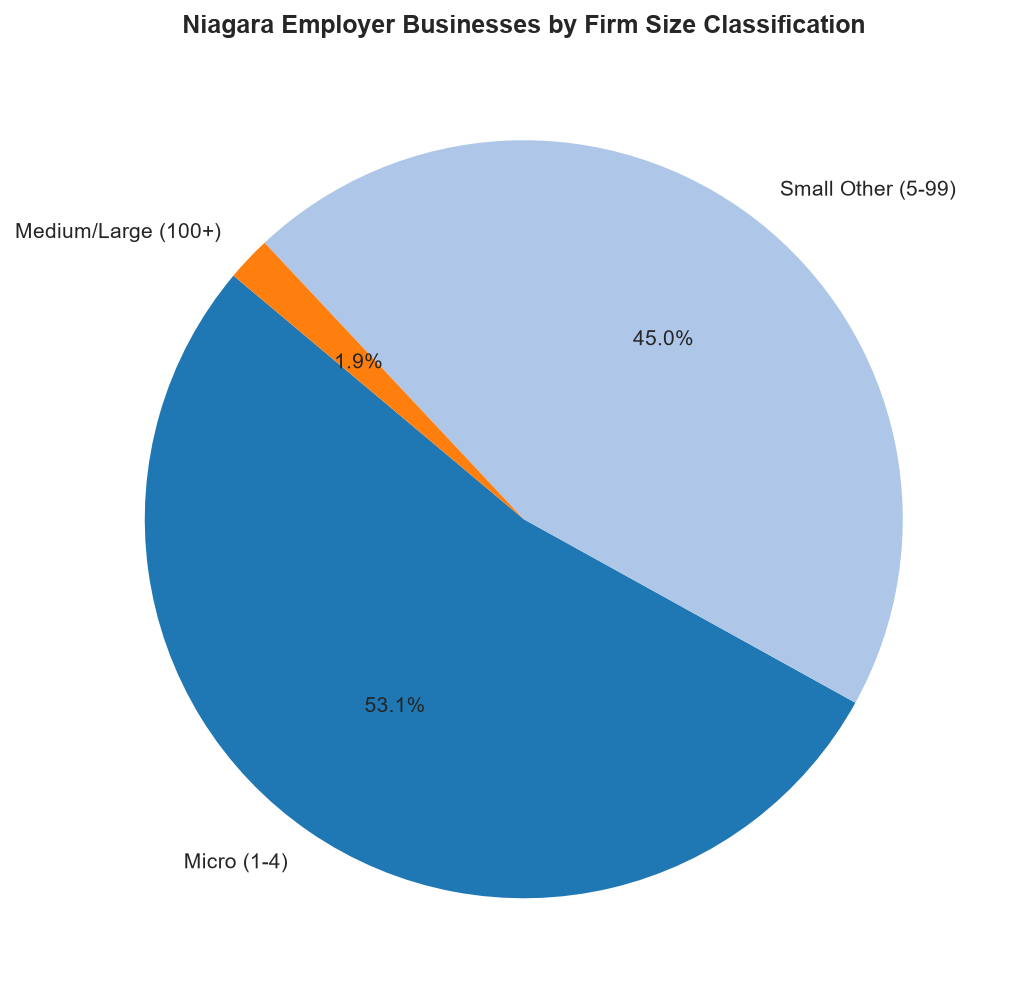

In [6]:
total_employer_val = df_total_ind[df_total_ind['Employment size'] == 'Total, with employees']['VALUE'].sum()
micro_val = df_total_ind[df_total_ind['Employment size'] == '1 to 4 employees']['VALUE'].sum()
small_val = df_total_ind[df_total_ind['Employment size'].isin([
    '1 to 4 employees', '5 to 9 employees', '10 to 19 employees',
    '20 to 49 employees', '50 to 99 employees'
])]['VALUE'].sum()

print(f'Total Employer Businesses (Denominator): {int(total_employer_val):,}')
print(f'Micro Businesses (1-4 employees): {int(micro_val):,} ({micro_val / total_employer_val * 100:.2f}%)')
print(f'Small Businesses (1-99 employees): {int(small_val):,} ({small_val / total_employer_val * 100:.2f}%)')

labels = ['Micro (1-4)', 'Small Other (5-99)', 'Medium/Large (100+)']
medium_large_val = total_employer_val - small_val
sizes = [micro_val, small_val - micro_val, medium_large_val]
colors = ['#1f77b4', '#aec7e8', '#ff7f0e']

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=colors)
ax.set_title('Niagara Employer Businesses by Firm Size Classification', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../../reports/figures/niagara_business_counts_small_business_share.png')
plt.show()

## Step 7: Compare with NEI Carefully
Document structural differences between StatCan Canadian Business Counts and the Niagara Employment Inventory (NEI).

In [7]:
nei_path = '../../data/interim/nei_cleaned.csv'
nei_df = pd.read_csv(nei_path, low_memory=False)

print(f'NEI Shape: {nei_df.shape[0]:,} rows, {nei_df.shape[1]} columns')

comparison_matrix = pd.DataFrame({
    'Dimension': ['Geographic Unit', 'Target Entity', 'Reference Vintage', 'Industry Scheme', 'Granularity'],
    'StatCan Canadian Business Counts': [
        '12 Census Subdivisions (CSDs)',
        'Employer business registry locations',
        'Snapshot: 2026-01',
        'NAICS 2022 (hierarchical)',
        'Aggregated counts by size/NAICS'
    ],
    'Niagara Employment Inventory (NEI)': [
        'Municipal points / address parcels',
        'Surveyed local physical establishments',
        'Annual municipal survey cycles',
        'NAICS / Local land-use codes',
        'Establishment-level microdata'
    ]
})
print(comparison_matrix.to_string(index=False))
comparison_matrix.to_csv('../../reports/figures/cbc_nei_comparison_matrix.csv', index=False)

NEI Shape: 98,065 rows, 20 columns
        Dimension     StatCan Canadian Business Counts     Niagara Employment Inventory (NEI)
  Geographic Unit        12 Census Subdivisions (CSDs)     Municipal points / address parcels
    Target Entity Employer business registry locations Surveyed local physical establishments
Reference Vintage                    Snapshot: 2026-01         Annual municipal survey cycles
  Industry Scheme            NAICS 2022 (hierarchical)           NAICS / Local land-use codes
      Granularity      Aggregated counts by size/NAICS          Establishment-level microdata


## Step 8: Write Findings

### Finding 1: Extreme Small-Business Skew
- **Micro-enterprises (1-4 employees):** Account for 53.07% (7,639 of 14,395 employer businesses).
- **Small businesses (1-99 employees):** Account for 98.09% (14,121 of 14,395 employer businesses).
- Succession planning interventions must address micro-enterprises where formal transition planning is typically absent.

### Finding 2: Key Sector Exposures in Niagara
- High business concentrations are present in Construction, Real Estate, Retail Trade, and Accommodation and Food Services.
- High-touch local services and trade contracting represent the bulk of Niagara business continuity exposure.

### Finding 3: Analytical Alignment with NEI
- StatCan CBC captures tax/payroll employer units at CSD aggregate level, whereas NEI tracks physical establishments with parcel and spatial coordinates.
- The datasets cannot be joined at an establishment level; they must be cross-analyzed at aggregated industry-by-CSD levels.